In [1]:
import warnings, json, random, sys, platform, subprocess, importlib
import importlib.metadata as imd
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
sys.path.insert(0, str(Path.cwd()))

DATA_PATH  = Path("load_data.csv")
OUT        = Path("outputs");  OUT.mkdir(exist_ok=True)
FIG        = OUT / "figures";  FIG.mkdir(exist_ok=True)
TEST_START = pd.Timestamp("2018-12-01")          # last month of data = final hold-out

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

## 2. Data audit

In [2]:
raw_original = pd.read_csv(DATA_PATH)                  # exactly as delivered (original column names)
print("shape:", raw_original.shape); display(raw_original.head())
print("original columns:", list(raw_original.columns))

shape: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


original columns: ['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type']


In [3]:
audit = pd.DataFrame({
    "dtype": raw_original.dtypes.astype(str),
    "missing": raw_original.isna().sum(),
    "missing_%": (raw_original.isna().mean() * 100).round(2),
    "min": raw_original.min(numeric_only=True),
    "median": raw_original.median(numeric_only=True),
    "max": raw_original.max(numeric_only=True)})
display(audit)

,dtype,missing,missing_%,min,median,max
CO2(tCO2),float64,455,1.30,0.0,0.00,0.188166
Date_Time,str,0,0.00,NaN,NaN,NaN
Lagging_Current_Power_Factor,float64,350,1.00,0.0,90.08,299.996814
Lagging_Current_Reactive.Power_kVarh,float64,876,2.50,0.0,5.18,262.630718
Leading_Current_Power_Factor,float64,1471,4.20,0.0,100.00,299.969494
Leading_Current_Reactive_Power_kVarh,float64,1156,3.30,0.0,0.00,78.809000
Load_Type,str,0,0.00,NaN,NaN,NaN
NSM,float64,455,1.30,0.0,45000.00,248821.810465
Usage_kWh,float64,1559,4.45,0.0,5.29,435.019069


The audit below uses short column names; the mapping original → short name lives in the pipeline module (section 3), which is also what inference uses.

## 3. Pipeline code → `load_type_pipeline.py`


In [4]:
%%writefile load_type_pipeline.py
# =====================================================================================
# load_type_pipeline.py – cleaning, features, baseline & inference for Load_Type model.
# Imported by the training notebook and shipped with the saved model bundle.
# =====================================================================================
import warnings
import joblib
import sklearn
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin

CLASSES  = ["Light_Load", "Medium_Load", "Maximum_Load"]
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}
RENAME = {"Date_Time": "timestamp", "Usage_kWh": "usage_kwh",
          "Lagging_Current_Reactive.Power_kVarh": "lag_kvarh",
          "Leading_Current_Reactive_Power_kVarh": "lead_kvarh",
          "CO2(tCO2)": "co2", "Lagging_Current_Power_Factor": "lag_pf",
          "Leading_Current_Power_Factor": "lead_pf", "NSM": "nsm_raw", "Load_Type": "load_type"}
SENSORS  = ["usage_kwh", "lag_kvarh", "lead_kvarh", "co2", "lag_pf", "lead_pf"]
CAP_COLS = ["usage_kwh", "lag_kvarh", "lead_kvarh", "co2"]
UNBOUNDED = 1e12
VALID_RANGES = {"usage_kwh": (0.0, UNBOUNDED), "lag_kvarh": (0.0, UNBOUNDED), "lead_kvarh": (0.0, UNBOUNDED),
                "co2": (0.0, UNBOUNDED), "lag_pf": (0.0, 100.0), "lead_pf": (0.0, 100.0)}
WINTER_MONTHS    = [11, 12, 1, 2]       # Nov-Feb tariff season (identified in the EDA)
MIN_HISTORY_ROWS = 96                   # 24 h of 15-min readings (size of the longest rolling window)

CAL  = ["slot", "dow", "is_weekend", "is_winter", "slot_sin", "slot_cos"]
ELEC = SENSORS + ["reactive_ratio", "n_missing_raw"]
TEMP = ["usage_lag1", "usage_lag4", "usage_diff1", "usage_roll4_mean", "usage_roll4_std",
        "usage_roll16_mean", "usage_roll96_mean"]
ALL  = CAL + ELEC + TEMP


def normalise_schema(df):
    # Accept original CSV names or already-normalised names; validate required columns.
    d = df.rename(columns=RENAME).copy()
    missing = [c for c in ["timestamp"] + SENSORS if c not in d.columns]
    if missing:
        inv = {v: k for k, v in RENAME.items()}
        missing = [inv.get(c, c) for c in missing]
        raise ValueError(f"Input is missing required column(s) {missing}. "
                         f"Expected the original CSV columns {list(RENAME)[:7]} (or their normalised names).")
    return d


def clean(raw_df):
    # Deterministic row-wise cleaning (no statistics learned from data -> safe before any split).
    d = normalise_schema(raw_df)
    d["timestamp"] = pd.to_datetime(d["timestamp"], format="%d-%m-%Y %H:%M")
    for c in SENSORS:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d["_na"] = d[SENSORS].isna().sum(axis=1)
    d = (d.sort_values(["timestamp", "_na"]).drop_duplicates("timestamp", keep="first")
           .drop(columns="_na").sort_values("timestamp").reset_index(drop=True))
    for c, (lo, hi) in VALID_RANGES.items():            # one consistent validity rule per column
        d.loc[(d[c] < lo) | (d[c] > hi), c] = np.nan
    d = d.drop(columns="nsm_raw", errors="ignore")      # re-derived from the timestamp as `slot`
    if "load_type" in d.columns:
        d["y"] = d["load_type"].map(LABEL2ID)
    return d


def make_features(d, caps):
    # All operations are causal (current / past rows only) -> safe to compute on the full series.
    f = pd.DataFrame(index=d.index)
    t = d["timestamp"]
    f["slot"]       = t.dt.hour * 4 + t.dt.minute // 15
    f["dow"]        = t.dt.dayofweek
    f["is_weekend"] = (f["dow"] >= 5).astype(int)
    f["is_winter"]  = t.dt.month.isin(WINTER_MONTHS).astype(int)
    f["slot_sin"]   = np.sin(2 * np.pi * f["slot"] / 96)
    f["slot_cos"]   = np.cos(2 * np.pi * f["slot"] / 96)
    s = d[SENSORS].copy()
    s[CAP_COLS] = s[CAP_COLS].clip(upper=caps, axis=1)  # caps fitted on TRAIN only
    f["n_missing_raw"] = s.isna().sum(axis=1)
    s = s.ffill(limit=4)                                # causal gap fill, max 1 hour
    for c in SENSORS:
        f[c] = s[c]
    f["reactive_ratio"] = s["lag_kvarh"] / (s["usage_kwh"] + 1)
    u = s["usage_kwh"]
    f["usage_lag1"]        = u.shift(1)
    f["usage_lag4"]        = u.shift(4)
    f["usage_diff1"]       = u - u.shift(1)
    f["usage_roll4_mean"]  = u.rolling(4,  min_periods=1).mean()
    f["usage_roll4_std"]   = u.rolling(4,  min_periods=2).std()
    f["usage_roll16_mean"] = u.rolling(16, min_periods=1).mean()
    f["usage_roll96_mean"] = u.rolling(96, min_periods=1).mean()
    return f


def check_history(d, min_rows=MIN_HISTORY_ROWS):
    # Warn (never reject) when history is short or the 15-min grid has gaps; flag rows with a full 24 h window.
    t = d["timestamp"]
    n_gaps = int((t.diff().dropna() != pd.Timedelta("15min")).sum())
    if len(d) < min_rows:
        warnings.warn(f"Only {len(d)} readings supplied (< {min_rows} = 24 h). Rolling 24 h features are computed "
                      f"on a partial window; predictions at the start are less reliable.")
    elif n_gaps:
        warnings.warn(f"{n_gaps} gap(s)/irregular step(s) in the 15-min time grid; rolling features assume a regular grid.")
    return ((t - t.shift(min_rows - 1)) == pd.Timedelta(minutes=15 * (min_rows - 1))).rename("full_24h_history")


class RuleBaseline(ClassifierMixin, BaseEstimator):
    # Majority label per (time-slot, season, weekday) – learned from the training rows only.
    def fit(self, X, y):
        d = pd.DataFrame({"s": np.asarray(X["slot"]), "w": np.asarray(X["is_winter"]),
                          "d": np.asarray(X["dow"]), "y": np.asarray(y)})
        mode = lambda s: s.value_counts().idxmax()
        self.full_ = d.groupby(["s", "w", "d"])["y"].agg(mode).to_dict()
        self.slot_ = d.groupby(["s", "w"])["y"].agg(mode).to_dict()
        self.global_ = int(mode(d["y"]))
        self.classes_ = np.unique(d["y"])
        return self

    def predict(self, X):
        out = []
        for s, w, dd in zip(X["slot"], X["is_winter"], X["dow"]):
            out.append(self.full_.get((s, w, dd), self.slot_.get((s, w), self.global_)))
        return np.array(out)


def predict_from_raw(raw_df, bundle):
    # End-to-end inference: ORIGINAL CSV rows -> predicted Load_Type (+ probabilities, + history flag).
    d = clean(raw_df)
    full = check_history(d)
    X = make_features(d, bundle["caps"])[bundle["features"]]
    proba = bundle["model"].predict_proba(X)
    out = d[["timestamp"]].copy()
    out["predicted_load_type"] = [bundle["classes"][i] for i in proba.argmax(1)]
    for i, c in enumerate(bundle["classes"]):
        out[f"p_{c}"] = proba[:, i].round(4)
    out["full_24h_history"] = full.values
    return out


def load_bundle(path):
    b = joblib.load(path)
    if b["versions"]["scikit-learn"] != sklearn.__version__:
        warnings.warn(f"Model trained with scikit-learn {b['versions']['scikit-learn']}, "
                      f"running {sklearn.__version__}: results may differ.")
    return b

Overwriting load_type_pipeline.py


In [5]:
import load_type_pipeline as LTP
importlib.reload(LTP)
from load_type_pipeline import (CLASSES, LABEL2ID, RENAME, SENSORS, CAP_COLS, VALID_RANGES, WINTER_MONTHS,
                                CAL, ELEC, TEMP, ALL, clean, make_features, RuleBaseline, predict_from_raw)
print("pipeline module loaded:", LTP.__file__)

pipeline module loaded: c:\Users\srini\Downloads\Load_Type_Project\Load_Type_Project\load_type_pipeline.py


### 3a. Audit of the raw data (evidence for each cleaning rule)

In [6]:
raw = raw_original.rename(columns=RENAME)
ts = pd.to_datetime(raw["timestamp"], format="%d-%m-%Y %H:%M")

print("rows:", len(raw), "| unique timestamps:", ts.nunique(), "| duplicated timestamps:", ts.duplicated().sum())
display(raw[ts.duplicated(keep=False)])
u = ts.drop_duplicates().sort_values()
print("perfect 15-min grid after de-dup:", bool((u.diff().dropna() == pd.Timedelta("15min")).all()),
      "|", u.min(), "->", u.max(), "|", len(u), "expected", 365 * 96)

nsm_true = ts.dt.hour * 3600 + ts.dt.minute * 60
m = raw["nsm_raw"].notna()
print(f"\nNSM inconsistent with timestamp : {(raw.loc[m,'nsm_raw'] != nsm_true[m]).mean():.1%} of non-null rows")
print(f"NSM > 86,400 (impossible)        : {(raw['nsm_raw'] > 86400).sum()} rows")

print("\nValues outside the valid range (set to NaN by clean()):")
inv = {c: int(((raw[c] < lo) | (raw[c] > hi)).sum()) for c, (lo, hi) in VALID_RANGES.items()}
display(pd.Series(inv, name="invalid values").to_frame().assign(valid_range=[f"[{lo:g}, {'inf' if hi > 1e11 else f'{hi:g}'}]" for lo, hi in VALID_RANGES.values()]))
for c in CAP_COLS:
    print(f"{c:10s} p99={raw[c].quantile(.99):8.2f}  p99.9={raw[c].quantile(.999):8.2f}  max={raw[c].max():8.2f}")

rows: 35041 | unique timestamps: 35040 | duplicated timestamps: 1


,timestamp,usage_kwh,lag_kvarh,lead_kvarh,co2,lag_pf,lead_pf,nsm_raw,load_type
35023,31-12-2018 20:00,4.14,0.0,20.09,0.0,100.00000,20.18,72000.0,Light_Load
35040,31-12-2018 20:00,NaN,0.0,20.10,0.0,217.27347,20.19,72000.0,Light_Load


perfect 15-min grid after de-dup: True | 2018-01-01 00:00:00 -> 2018-12-31 23:45:00 | 35040 expected 35040

NSM inconsistent with timestamp : 9.9% of non-null rows
NSM > 86,400 (impossible)        : 1773 rows

Values outside the valid range (set to NaN by clean()):


,invalid values,valid_range
usage_kwh,0,"[0, inf]"
lag_kvarh,0,"[0, inf]"
lead_kvarh,0,"[0, inf]"
co2,0,"[0, inf]"
lag_pf,3226,"[0, 100]"
lead_pf,2685,"[0, 100]"


usage_kwh  p99=  176.88  p99.9=  297.89  max=  435.02
lag_kvarh  p99=   90.93  p99.9=  154.78  max=  262.63
lead_kvarh p99=   39.89  p99.9=   67.27  max=   78.81
co2        p99=    0.08  p99.9=    0.14  max=    0.19


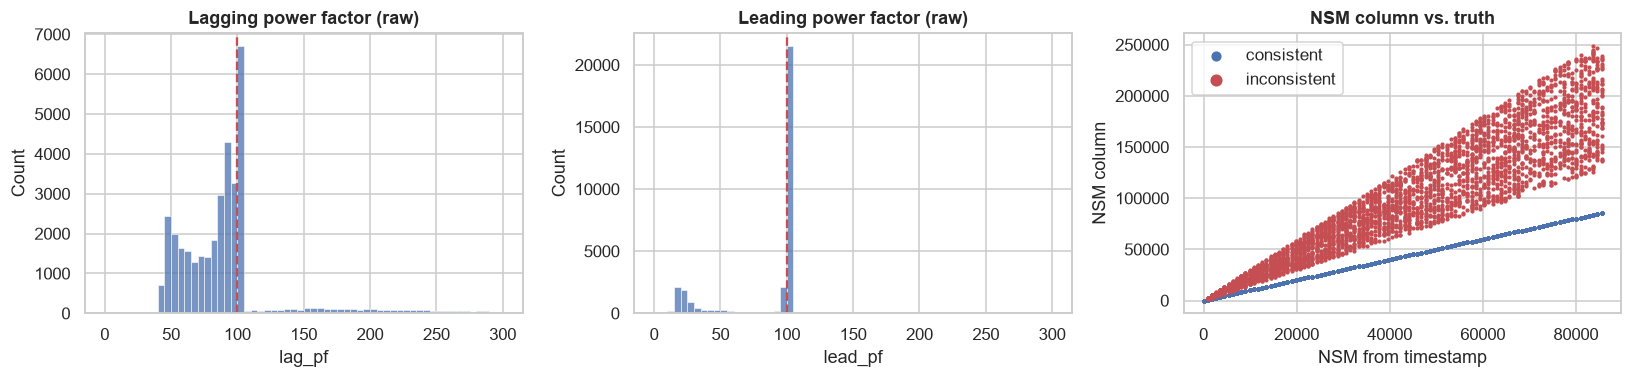

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(raw["lag_pf"].dropna(), bins=60, ax=ax[0]);  ax[0].axvline(100, c="r", ls="--"); ax[0].set_title("Lagging power factor (raw)")
sns.histplot(raw["lead_pf"].dropna(), bins=60, ax=ax[1]); ax[1].axvline(100, c="r", ls="--"); ax[1].set_title("Leading power factor (raw)")
bad = (raw["nsm_raw"] != nsm_true) & raw["nsm_raw"].notna()
ax[2].scatter(nsm_true[~bad], raw.loc[~bad, "nsm_raw"], s=2, label="consistent")
ax[2].scatter(nsm_true[bad], raw.loc[bad, "nsm_raw"], s=3, c="r", label="inconsistent")
ax[2].set_xlabel("NSM from timestamp"); ax[2].set_ylabel("NSM column"); ax[2].legend(markerscale=4); ax[2].set_title("NSM column vs. truth")
savefig("01_data_quality")

| # | Finding | Decision |
|---|---|---|
| 1 | Every sensor column has 1–4 % missing values | Causal forward-fill (≤ 1 h), then training-median imputation inside the model pipeline; keep `n_missing_raw` |
| 2 | 1 duplicated timestamp (one copy has NaN usage) | Keep the more complete copy |
| 3 | `NSM` wrong in ~11 % of rows, up to > 86,400 s | Drop it – recomputed from the timestamp as `slot` |
| 4 | Power factors up to 300 % | Enforce the full valid range 0–100 → invalid = NaN |
| 5 | Heavy-tailed energy columns (usage up to 435 kWh) | Winsorise at the **training-set** 99.5th percentile |
| 6 | Timestamp is a `dd-mm-yyyy` string | Parse with an explicit format |

In [8]:
df = clean(raw_original)                               # note: the ORIGINAL column names go in
is_train = df["timestamp"] < TEST_START
print(f"clean rows: {len(df):,} | train: {is_train.sum():,} ({df.loc[is_train,'timestamp'].min():%d %b} – {df.loc[is_train,'timestamp'].max():%d %b %Y})"
      f" | final hold-out: {(~is_train).sum():,} ({df.loc[~is_train,'timestamp'].min():%d %b} – {df.loc[~is_train,'timestamp'].max():%d %b %Y})")
assert df["timestamp"].is_unique and df["y"].notna().all()

clean rows: 35,040 | train: 32,064 (01 Jan – 30 Nov 2018) | final hold-out: 2,976 (01 Dec – 31 Dec 2018)


## 4. Exploratory Data Analysis
*The plots below use the **training period only**.*

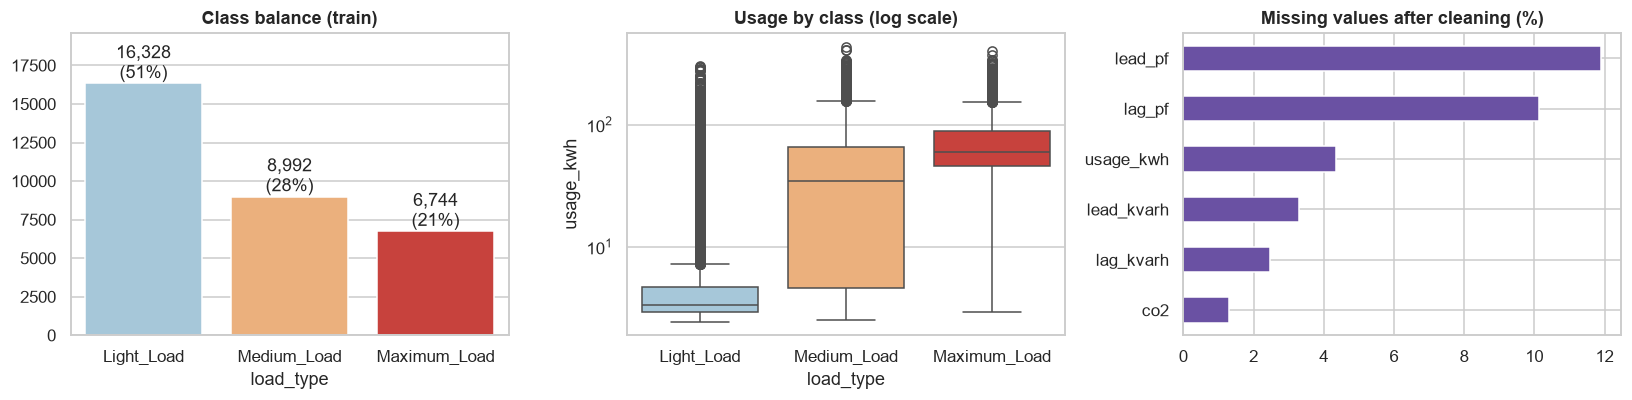

In [9]:
eda = df[is_train].copy()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cnt = eda["load_type"].value_counts().reindex(CLASSES)
sns.barplot(x=cnt.index, y=cnt.values, ax=ax[0], palette=["#9ecae1", "#fdae6b", "#de2d26"])
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v:,}\n({v/cnt.sum():.0%})", ha="center", va="bottom")
ax[0].set_title("Class balance (train)"); ax[0].set_ylim(0, cnt.max() * 1.2)
sns.boxplot(data=eda[eda.usage_kwh > 0], x="load_type", y="usage_kwh", order=CLASSES, ax=ax[1], palette=["#9ecae1", "#fdae6b", "#de2d26"])
ax[1].set_yscale("log"); ax[1].set_title("Usage by class (log scale)")
eda[SENSORS].isna().mean().mul(100).sort_values().plot.barh(ax=ax[2], color="#6a51a3"); ax[2].set_title("Missing values after cleaning (%)")
savefig("02_overview")

Usage overlaps heavily between classes, so energy usage alone cannot define the label. Let's look at the label **over time**.

Distinct 24-hour label patterns in the training period: 3


month,1,2,3,4,5,6,7,8,9,10,11
daily pattern,,,,,,,,,,,
Off-day (all Light),4,9,3,3,5,5,2,8,7,4,3
Working day – Mar-Oct tariff,0,0,28,27,26,25,29,23,23,27,0
Working day – Nov-Feb tariff,27,19,0,0,0,0,0,0,0,0,27


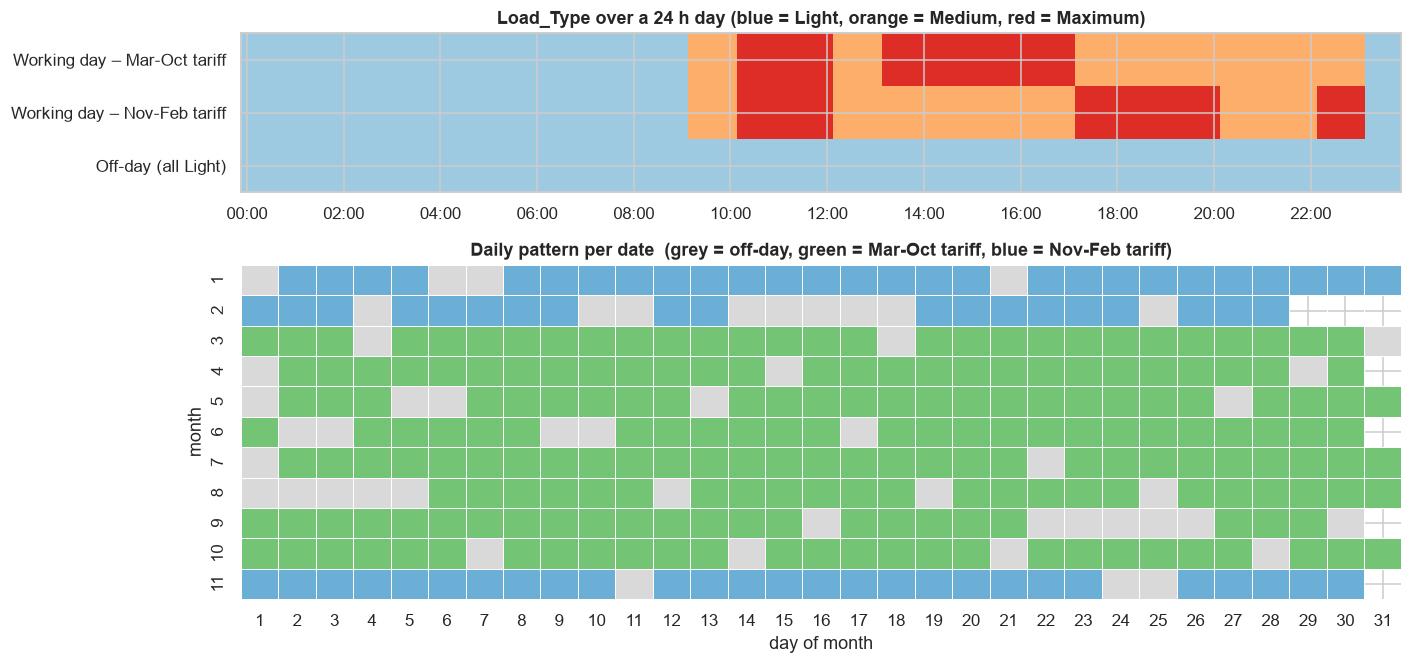

In [10]:
eda["date"] = eda["timestamp"].dt.normalize()
sym = {0: "L", 1: "M", 2: "X"}
daily_pattern = eda.groupby("date")["y"].apply(lambda s: "".join(s.map(sym)))
print("Distinct 24-hour label patterns in the training period:", daily_pattern.nunique())
order = daily_pattern.value_counts().index
months_of = {p: sorted(daily_pattern[daily_pattern == p].index.month.unique()) for p in order}
names = {}
for p in order:
    if set(p) == {"L"}:                    names[p] = "Off-day (all Light)"
    elif set(months_of[p]) <= {1,2,11,12}: names[p] = "Working day – Nov-Feb tariff"
    else:                                  names[p] = "Working day – Mar-Oct tariff"
pat_name = daily_pattern.map(names)
display(pd.crosstab(pat_name, daily_pattern.index.month).rename_axis(index="daily pattern", columns="month"))

cmap = {"L": 0, "M": 1, "X": 2}
fig, ax = plt.subplots(2, 1, figsize=(13, 6.2), gridspec_kw={"height_ratios": [1, 2.1]})
strip = np.array([[cmap[ch] for ch in p] for p in order])
ax[0].imshow(strip, aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#9ecae1", "#fdae6b", "#de2d26"]))
ax[0].set_yticks(range(len(order))); ax[0].set_yticklabels([names[p] for p in order])
ax[0].set_xticks(np.arange(0, 96, 8)); ax[0].set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])
ax[0].set_title("Load_Type over a 24 h day (blue = Light, orange = Medium, red = Maximum)")
cal = pd.DataFrame({"m": daily_pattern.index.month, "d": daily_pattern.index.day, "p": pat_name.values})
codes = {"Off-day (all Light)": 0, "Working day – Mar-Oct tariff": 1, "Working day – Nov-Feb tariff": 2}
grid = cal.assign(c=cal.p.map(codes)).pivot(index="m", columns="d", values="c")
sns.heatmap(grid, cmap=["#d9d9d9", "#74c476", "#6baed6"], cbar=False, linewidths=.4, ax=ax[1])
ax[1].set_title("Daily pattern per date  (grey = off-day, green = Mar-Oct tariff, blue = Nov-Feb tariff)")
ax[1].set_xlabel("day of month"); ax[1].set_ylabel("month")
savefig("03_label_structure")

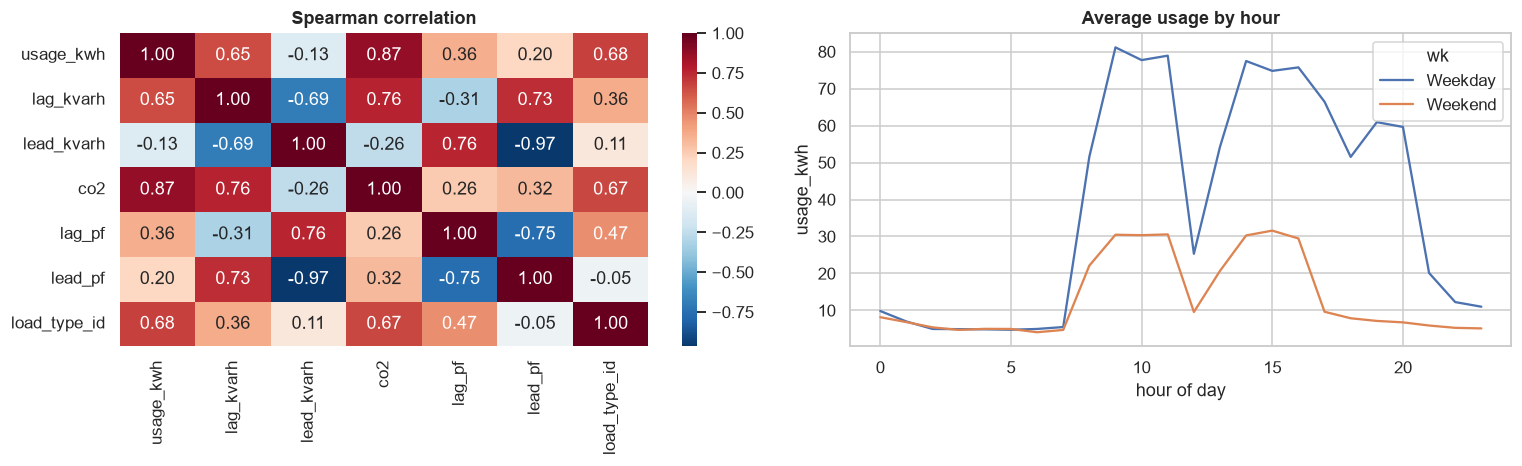

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
num = eda[SENSORS + ["y"]].rename(columns={"y": "load_type_id"})
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0]); ax[0].set_title("Spearman correlation")
wd = eda.assign(hr=eda.timestamp.dt.hour, wk=np.where(eda.timestamp.dt.dayofweek >= 5, "Weekend", "Weekday"))
sns.lineplot(data=wd, x="hr", y="usage_kwh", hue="wk", errorbar=None, ax=ax[1]); ax[1].set_title("Average usage by hour"); ax[1].set_xlabel("hour of day")
savefig("04_correlation_profile")

## 5. Feature engineering (implemented in `make_features`)



In [12]:
caps = df.loc[is_train, CAP_COLS].quantile(0.995)           # fitted on TRAIN only
print("winsorisation caps (train p99.5):\n", caps.round(3).to_string())
X_all = make_features(df, caps)
X_train, y_train = X_all.loc[is_train, ALL], df.loc[is_train, "y"]
X_test,  y_test  = X_all.loc[~is_train, ALL], df.loc[~is_train, "y"]
print(f"\nfeatures: {len(ALL)} | X_train {X_train.shape} | X_test {X_test.shape}")
display(X_train.describe().T[["count", "mean", "min", "max"]].round(2))

winsorisation caps (train p99.5):
 usage_kwh     226.398
lag_kvarh     111.666
lead_kvarh     47.544
co2             0.106

features: 21 | X_train (32064, 21) | X_test (2976, 21)


,count,mean,min,max
slot,32064.0,47.50,0.00,95.00
dow,32064.0,2.99,0.00,6.00
is_weekend,32064.0,0.28,0.00,1.00
is_winter,32064.0,0.27,0.00,1.00
slot_sin,32064.0,-0.00,-1.00,1.00
slot_cos,32064.0,-0.00,-1.00,1.00
usage_kwh,32064.0,31.33,0.00,226.40
lag_kvarh,32064.0,15.06,0.00,111.67
lead_kvarh,32064.0,4.16,0.00,47.54
co2,32064.0,0.01,0.00,0.11


## 6. Validation design

| Stage | Data | Purpose |
|---|---|---|
| **Primary model selection & tuning** | **Expanding-window forward CV** on Jan–Nov: train on all months before month *m*, validate on month *m*, for *m* = Jul, Aug, Sep, Oct, Nov | Chronologically honest: validation is always *after* the training data |
| **Final hold-out** | Train on Jan–Nov → test on **December** | Final report and post-hoc diagnostics (see the note in section 1) |




In [13]:
months = df.loc[is_train, "timestamp"].dt.month.values
FWD_VALID_MONTHS = [7, 8, 9, 10, 11]
fwd_splits = [(np.where(months < m)[0], np.where(months == m)[0]) for m in FWD_VALID_MONTHS]

display(pd.DataFrame({
    "validate on month": FWD_VALID_MONTHS,
    "train on months": [f"1 – {m-1}" for m in FWD_VALID_MONTHS],
    "n_train": [len(a) for a, b in fwd_splits],
    "n_valid": [len(b) for a, b in fwd_splits],
}).set_index("validate on month"))

# Chronological sanity check: validation must be later than every training row.
ts_train = df.loc[is_train, "timestamp"].values
assert all(ts_train[a].max() < ts_train[b].min() for a, b in fwd_splits)
print("✔ all folds are strictly forward in time")

# Each split indexes positions within the January–November training subset.
TRAIN_POS = np.flatnonzero(is_train.values)

def prepare_fold_features(train_idx, valid_idx, frame=None):
    """Build one fold's features using caps learned only from that fold's training rows."""
    frame = df if frame is None else frame
    tr_rows = TRAIN_POS[train_idx]
    va_rows = TRAIN_POS[valid_idx]

    # Critical leakage fix: do not calculate caps from later validation/future months.
    fold_caps = frame.iloc[tr_rows][CAP_COLS].quantile(0.995)

    # make_features uses causal forward-fill, shifts, and trailing rolling windows.
    fold_X = make_features(frame, fold_caps)
    return (
        fold_X.iloc[tr_rows][ALL],
        fold_X.iloc[va_rows][ALL],
        frame.iloc[tr_rows]["y"],
        frame.iloc[va_rows]["y"],
    )

# Cache fold features so model comparison, tuning, and ablation all use the same safe fold inputs.
fold_data = [prepare_fold_features(a, b) for a, b in fwd_splits]

# Leakage regression test: corrupting data after the training cutoff must not change training features.
for k, (tr, va) in enumerate(fwd_splits):
    train_rows = TRAIN_POS[tr]
    valid_rows = TRAIN_POS[va]
    last_train_ts = df.iloc[train_rows]["timestamp"].max()

    tampered = df.copy()
    future = tampered["timestamp"] > last_train_ts
    tampered.loc[future, SENSORS] = tampered.loc[future, SENSORS] * 50

    X_train_before = fold_data[k][0]
    X_train_after = prepare_fold_features(tr, va, frame=tampered)[0]
    pd.testing.assert_frame_equal(X_train_before, X_train_after)
    assert last_train_ts < df.iloc[valid_rows]["timestamp"].min()

print("✔ fold-specific caps verified; future-data tampering leaves training features unchanged")


,train on months,n_train,n_valid
validate on month,,,
7,1 – 6,17376,2976
8,1 – 7,20352,2976
9,1 – 8,23328,2880
10,1 – 9,26208,2976
11,1 – 10,29184,2880


✔ all folds are strictly forward in time
✔ fold-specific caps verified; future-data tampering leaves training features unchanged


## 7. Model selection 


,cv_accuracy,cv_f1_macro,cv_f1_std
model,,,
Decision Tree,0.9909,0.9900,0.0076
HistGradientBoosting,0.9896,0.9895,0.0084
Random Forest,0.9859,0.9844,0.0144
Rule baseline (slot × season × weekday),0.9311,0.9302,0.0443
Logistic Regression,0.8574,0.8287,0.1302
Dummy (most frequent),0.5082,0.2243,0.0129


,val 07,val 08,val 09,val 10,val 11
macro-F1 per validation month,,,,,
Dummy (most frequent),0.2083,0.2413,0.2373,0.2198,0.2147
Rule baseline (slot × season × weekday),0.9441,0.8845,0.8802,1.0000,0.9422
Logistic Regression,0.8960,0.8855,0.8747,0.9173,0.5697
Decision Tree,0.9994,0.9790,0.9949,0.9933,0.9834
Random Forest,0.9948,0.9777,0.9981,0.9923,0.9592
HistGradientBoosting,1.0000,0.9789,0.9973,0.9899,0.9813


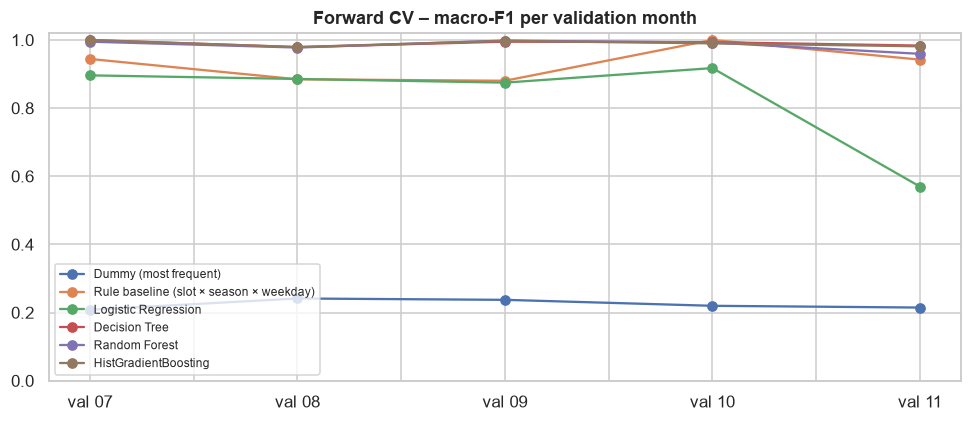

In [14]:
def make_pipe(est, scale=False):
    steps = [("impute", SimpleImputer(strategy="median"))]  # fitted on training fold only
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("clf", est))
    return Pipeline(steps)

RULE = "Rule baseline (slot × season × weekday)"
models = {
    "Dummy (most frequent)": make_pipe(DummyClassifier(strategy="most_frequent")),
    RULE: RuleBaseline(),
    "Logistic Regression": make_pipe(
        LogisticRegression(max_iter=3000, class_weight="balanced"), scale=True
    ),
    "Decision Tree": make_pipe(
        DecisionTreeClassifier(max_depth=12, min_samples_leaf=5,
                               class_weight="balanced", random_state=SEED)
    ),
    "Random Forest": make_pipe(
        RandomForestClassifier(n_estimators=100, min_samples_leaf=2,
                               class_weight="balanced", n_jobs=1, random_state=SEED)
    ),
    "HistGradientBoosting": make_pipe(
        HistGradientBoostingClassifier(random_state=SEED)
    ),
}

def cv_score(est, cols=None):
    """Return mean fold accuracy, mean macro-F1, population std, and per-fold F1."""
    accs, f1s = [], []
    for Xtr, Xva, ytr, yva in fold_data:
        if cols is not None:
            Xtr, Xva = Xtr[cols], Xva[cols]
        fitted_fold = clone(est).fit(Xtr, ytr)
        pred = fitted_fold.predict(Xva)
        accs.append(accuracy_score(yva, pred))
        f1s.append(f1_score(yva, pred, average="macro", zero_division=0))
    return float(np.mean(accs)), float(np.mean(f1s)), float(np.std(f1s, ddof=0)), np.asarray(f1s)

cv_rows, cv_folds = [], {}
for name, est in models.items():
    acc, f1m, f1s, per_fold = cv_score(est)
    cv_folds[name] = per_fold
    cv_rows.append({
        "model": name, "cv_accuracy": acc,
        "cv_f1_macro": f1m, "cv_f1_std": f1s,
    })

cv_table = pd.DataFrame(cv_rows).set_index("model")
display(cv_table.sort_values("cv_f1_macro", ascending=False).round(4))

fold_df = pd.DataFrame(
    cv_folds, index=[f"val {m:02d}" for m in FWD_VALID_MONTHS]
).T
display(fold_df.round(4).rename_axis("macro-F1 per validation month"))
ax = fold_df.T.plot(marker="o", figsize=(9, 4))
ax.set_ylim(0, 1.02)
ax.set_title("Forward CV – macro-F1 per validation month")
ax.legend(fontsize=8, loc="lower left")
savefig("04b_forward_cv")


### Hyper-parameter tuning (forward CV)


In [15]:
param_dist = {
    "clf__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "clf__max_iter": [150, 250, 400],
    "clf__max_depth": [None, 4, 6, 8],
    "clf__max_leaf_nodes": [15, 31, 63],
    "clf__min_samples_leaf": [20, 50, 100],
    "clf__l2_regularization": [0.0, 0.1, 1.0],
    "clf__class_weight": [None, "balanced"],
}
base_hgb = make_pipe(HistGradientBoostingClassifier(random_state=SEED))

search_results = []
for params in ParameterSampler(param_dist, n_iter=8, random_state=SEED):
    candidate = clone(base_hgb).set_params(**params)
    acc, f1m, f1s, _ = cv_score(candidate)
    search_results.append({"params": params, "acc": acc, "f1": f1m, "std": f1s})

best = max(search_results, key=lambda r: r["f1"])
display(pd.DataFrame([
    {**{k.replace("clf__", ""): v for k, v in r["params"].items()},
     "cv_accuracy": r["acc"], "cv_f1_macro": r["f1"], "cv_f1_std": r["std"]}
    for r in search_results
]).sort_values("cv_f1_macro", ascending=False).round(4))

TUNED = "HistGradientBoosting (tuned)"
models[TUNED] = clone(base_hgb).set_params(**best["params"])
cv_table.loc[TUNED] = [best["acc"], best["f1"], best["std"]]
print("best params:", {k.replace("clf__", ""): v for k, v in best["params"].items()})


,min_samples_leaf,max_leaf_nodes,max_iter,max_depth,learning_rate,l2_regularization,class_weight,cv_accuracy,cv_f1_macro,cv_f1_std
0,100,31,400,8.0,0.20,0.1,NaN,0.9895,0.9894,0.0086
1,50,63,400,8.0,0.20,1.0,NaN,0.9894,0.9893,0.0090
4,20,15,400,NaN,0.20,0.0,balanced,0.9893,0.9892,0.0088
3,20,63,250,NaN,0.10,1.0,NaN,0.9893,0.9892,0.0090
7,100,31,400,4.0,0.20,1.0,NaN,0.9893,0.9892,0.0090
2,100,31,400,4.0,0.10,1.0,NaN,0.9892,0.9891,0.0093
5,20,15,250,NaN,0.03,1.0,balanced,0.9890,0.9889,0.0095
6,50,63,150,4.0,0.03,0.1,NaN,0.9852,0.9837,0.0162


best params: {'min_samples_leaf': 100, 'max_leaf_nodes': 31, 'max_iter': 400, 'max_depth': 8, 'learning_rate': 0.2, 'l2_regularization': 0.1, 'class_weight': None}


### Champion rule (declared before looking at any December score)


In [16]:
SIMPLICITY = ["Logistic Regression", "Decision Tree", "Random Forest", "HistGradientBoosting", TUNED]
MARGIN = 0.002
best_cv = cv_table.loc[SIMPLICITY, "cv_f1_macro"].max()
eligible = [m for m in SIMPLICITY if cv_table.loc[m, "cv_f1_macro"] >= best_cv - MARGIN]
CHAMPION = eligible[0]
print(f"best forward-CV macro-F1 = {best_cv:.4f} | eligible within {MARGIN}: {eligible}")
print(f"CHAMPION (simplest eligible) -> {CHAMPION}")
display(cv_table.sort_values("cv_f1_macro", ascending=False).round(4))

best forward-CV macro-F1 = 0.9900 | eligible within 0.002: ['Decision Tree', 'HistGradientBoosting', 'HistGradientBoosting (tuned)']
CHAMPION (simplest eligible) -> Decision Tree


,cv_accuracy,cv_f1_macro,cv_f1_std
model,,,
Decision Tree,0.9909,0.9900,0.0076
HistGradientBoosting,0.9896,0.9895,0.0084
HistGradientBoosting (tuned),0.9895,0.9894,0.0086
Random Forest,0.9859,0.9844,0.0144
Rule baseline (slot × season × weekday),0.9311,0.9302,0.0443
Logistic Regression,0.8574,0.8287,0.1302
Dummy (most frequent),0.5082,0.2243,0.0129


## 8. Final hold-out evaluation 

In [17]:
def metrics_dict(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": p, "recall_macro": r, "f1_macro": f, "f1_wtd": fw}

fitted, test_rows = {}, []
for name, est in models.items():
    m = clone(est).fit(X_train, y_train); fitted[name] = m
    test_rows.append({"model": name, **metrics_dict(y_test, m.predict(X_test))})
test_table = pd.DataFrame(test_rows).set_index("model")
comparison = cv_table[["cv_accuracy", "cv_f1_macro"]].join(test_table[["accuracy", "precision_macro", "recall_macro", "f1_macro"]])
comparison.columns = ["fwdCV acc", "fwdCV macro-F1", "Dec acc", "Dec macro-P", "Dec macro-R", "Dec macro-F1"]
display(comparison.sort_values("fwdCV macro-F1", ascending=False).round(4))
print("Champion was chosen on forward-CV columns only. (Tuned fwdCV is selection-biased.)")

,fwdCV acc,fwdCV macro-F1,Dec acc,Dec macro-P,Dec macro-R,Dec macro-F1
model,,,,,,
Decision Tree,0.9909,0.9900,0.9845,0.9839,0.9787,0.9813
HistGradientBoosting,0.9896,0.9895,0.9909,0.9949,0.9848,0.9898
HistGradientBoosting (tuned),0.9895,0.9894,0.9906,0.9947,0.9842,0.9894
Random Forest,0.9859,0.9844,0.9882,0.9895,0.9817,0.9855
Rule baseline (slot × season × weekday),0.9311,0.9302,0.8871,0.8595,0.9162,0.8824
Logistic Regression,0.8574,0.8287,0.7319,0.5853,0.5764,0.5753
Dummy (most frequent),0.5082,0.2243,0.5860,0.1953,0.3333,0.2463


Champion was chosen on forward-CV columns only. (Tuned fwdCV is selection-biased.)


FINAL MODEL: Decision Tree | final hold-out = December 2018 (2,976 readings)

              precision    recall  f1-score   support

  Light_Load     0.9858    0.9943    0.9900      1744
 Medium_Load     0.9813    0.9702    0.9757       704
Maximum_Load     0.9846    0.9716    0.9781       528

    accuracy                         0.9845      2976
   macro avg     0.9839    0.9787    0.9813      2976
weighted avg     0.9845    0.9845    0.9845      2976



,precision,recall,f1-score,support
Decision Tree – December,,,,
Light_Load,0.9858,0.9943,0.9900,1744.0
Medium_Load,0.9813,0.9702,0.9757,704.0
Maximum_Load,0.9846,0.9716,0.9781,528.0
macro avg,0.9839,0.9787,0.9813,2976.0
weighted avg,0.9845,0.9845,0.9845,2976.0


,precision,recall,f1-score,support
Rule baseline – December,,,,
Light_Load,0.9632,0.8394,0.8971,1744.0
Medium_Load,0.8077,0.9545,0.8750,704.0
Maximum_Load,0.8077,0.9545,0.8750,528.0
macro avg,0.8595,0.9162,0.8824,2976.0
weighted avg,0.8988,0.8871,0.8879,2976.0


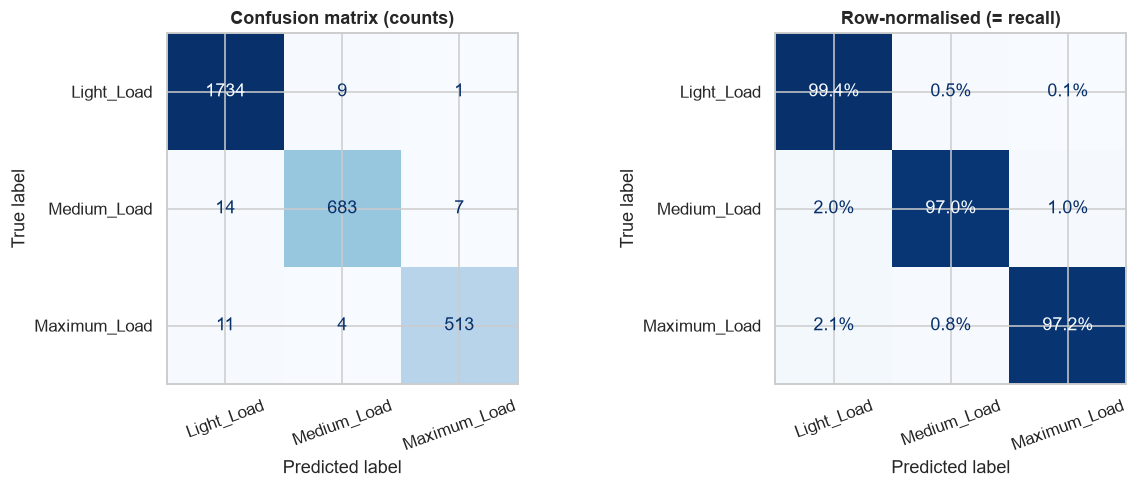

In [18]:
final_model = fitted[CHAMPION]
y_pred = final_model.predict(X_test)
final_metrics = metrics_dict(y_test, y_pred)
print(f"FINAL MODEL: {CHAMPION} | final hold-out = December 2018 ({len(y_test):,} readings)\n")
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))

def per_class(model):
    rep = classification_report(y_test, model.predict(X_test), target_names=CLASSES, output_dict=True, zero_division=0)
    return pd.DataFrame(rep).T.loc[CLASSES + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]]
pc_final, pc_rule = per_class(final_model), per_class(fitted[RULE])
display(pc_final.round(4).rename_axis(f"{CHAMPION} – December"))
display(pc_rule.round(4).rename_axis("Rule baseline – December"))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d"); ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"), display_labels=CLASSES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".1%"); ax[1].set_title("Row-normalised (= recall)")
for a in ax: a.set_xticklabels(CLASSES, rotation=20)
savefig("05_confusion_matrix")

## 9. Post-hoc diagnostics on the December hold-out
*These explain the result; they were **not** used to change features, parameters or the model.*

46 wrong predictions out of 2,976 (1.55%) | 11 of 31 days contain any error



,errors,readings,day,true_pattern
date,,,,
2018-12-01,23,96,Sat,Working day
2018-12-08,9,96,Sat,Working day
2018-12-09,1,96,Sun,Off-day
2018-12-15,2,96,Sat,Off-day
2018-12-16,1,96,Sun,Working day
2018-12-18,1,96,Tue,Working day
2018-12-19,1,96,Wed,Working day
2018-12-22,1,96,Sat,Off-day
2018-12-23,4,96,Sun,Off-day


December accuracy 0.9845 | day-block bootstrap 95% interval [0.9661, 0.9966]


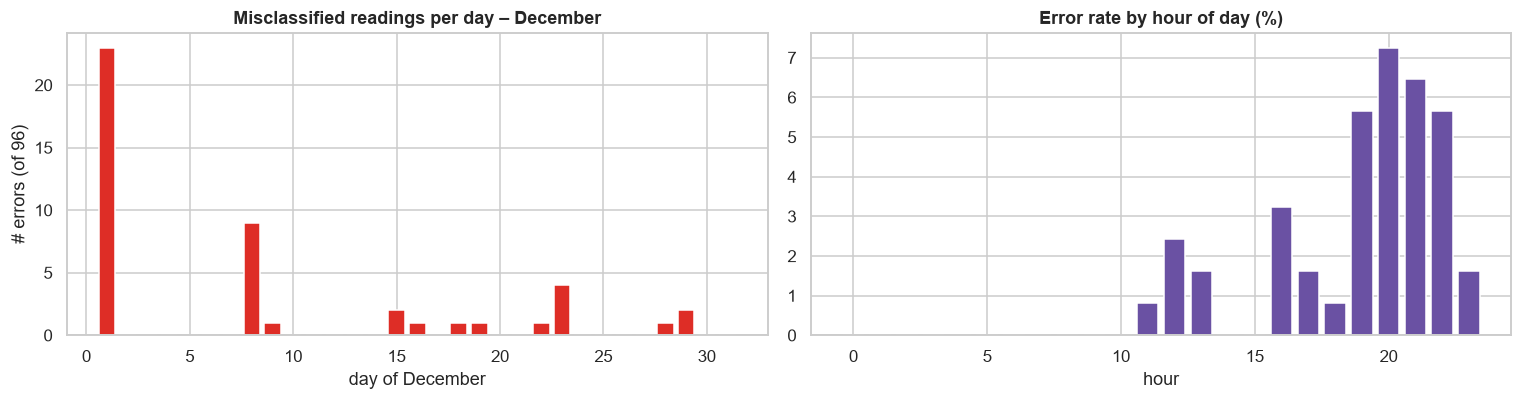

,readings,errors,error_rate
true_pattern,,,
Off-day,864,10,0.0116
Working day,2112,36,0.0170


share of errors within 1 reading of a true label change: 26.1%


In [19]:
res = df.loc[~is_train, ["timestamp", "y"]].copy()
res["pred"] = y_pred; res["wrong"] = res.y != res.pred; res["date"] = res.timestamp.dt.normalize()
by_day = res.groupby("date").agg(errors=("wrong", "sum"), readings=("wrong", "size"))
by_day["day"] = by_day.index.strftime("%a")
by_day["true_pattern"] = res.groupby("date")["y"].apply(lambda s: "Off-day" if (s == 0).all() else "Working day")
bad_days = by_day[by_day.errors > 0]
print(f"{res.wrong.sum()} wrong predictions out of {len(res):,} ({res.wrong.mean():.2%}) | {len(bad_days)} of {len(by_day)} days contain any error\n")
display(bad_days)

# day-block bootstrap: how uncertain is the December accuracy?  (resample whole days)
rng = np.random.default_rng(SEED); e, n = by_day.errors.values, by_day.readings.values
idx = rng.integers(0, len(e), (5000, len(e)))
boot_acc = 1 - e[idx].sum(1) / n[idx].sum(1)
acc_lo, acc_hi = np.percentile(boot_acc, [2.5, 97.5])
print(f"December accuracy {final_metrics['accuracy']:.4f} | day-block bootstrap 95% interval [{acc_lo:.4f}, {acc_hi:.4f}]")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].bar(by_day.index.day, by_day.errors, color=np.where(by_day.errors > 0, "#de2d26", "#74c476"))
ax[0].set_title("Misclassified readings per day – December"); ax[0].set_xlabel("day of December"); ax[0].set_ylabel("# errors (of 96)")
err_h = res.assign(h=res.timestamp.dt.hour).groupby("h")["wrong"].mean() * 100
ax[1].bar(err_h.index, err_h.values, color="#6a51a3"); ax[1].set_title("Error rate by hour of day (%)"); ax[1].set_xlabel("hour")
savefig("06_error_analysis")

res["true_pattern"] = res["date"].map(by_day["true_pattern"])
display(res.groupby("true_pattern").agg(readings=("wrong", "size"), errors=("wrong", "sum"), error_rate=("wrong", "mean")).round(4))
res["boundary"] = (res.y.ne(res.y.shift(1)) | res.y.ne(res.y.shift(-1)))
boundary_share = float(res.loc[res.wrong, "boundary"].mean()) if res.wrong.any() else 0.0
print(f"share of errors within 1 reading of a true label change: {boundary_share:.1%}")

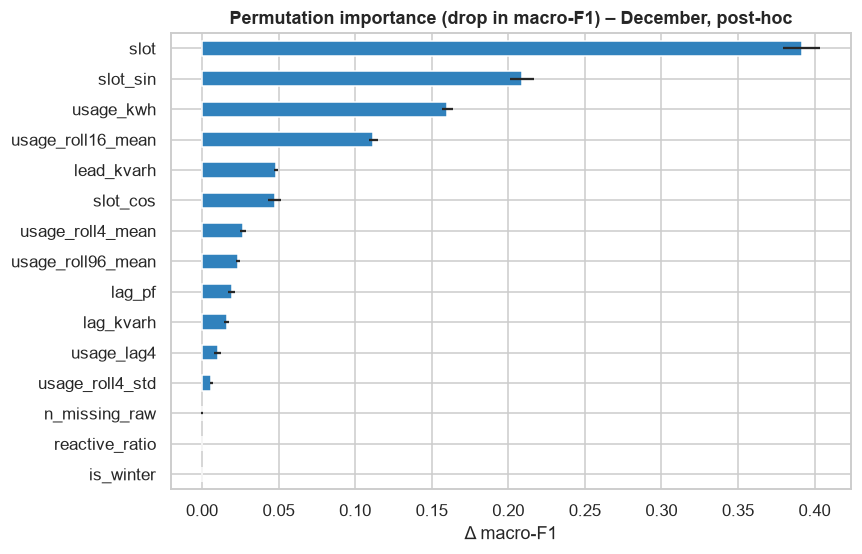

,importance
slot,0.3917
slot_sin,0.2091
usage_kwh,0.1602
usage_roll16_mean,0.1120
lead_kvarh,0.0485
slot_cos,0.0476
usage_roll4_mean,0.0268
usage_roll96_mean,0.0233


In [20]:
pi = permutation_importance(final_model, X_test, y_test, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=ALL).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.2))
imp.head(15)[::-1].plot.barh(xerr=pd.Series(pi.importances_std, index=ALL)[imp.head(15).index][::-1], ax=ax, color="#3182bd")
ax.set_title("Permutation importance (drop in macro-F1) – December, post-hoc"); ax.set_xlabel("Δ macro-F1")
savefig("07_permutation_importance")
display(imp.head(8).round(4).to_frame("importance"))

,n_features,fwdCV acc,fwdCV macro-F1,fwdCV macro-F1 std,Dec acc,Dec macro-F1
feature set,,,,,,
1. Calendar only,6,0.9063,0.9075,0.0418,0.8629,0.8585
2. Calendar + Electrical,14,0.9475,0.9482,0.0240,0.9405,0.9329
3. + Temporal (final feature set),21,0.9909,0.9900,0.0076,0.9845,0.9813


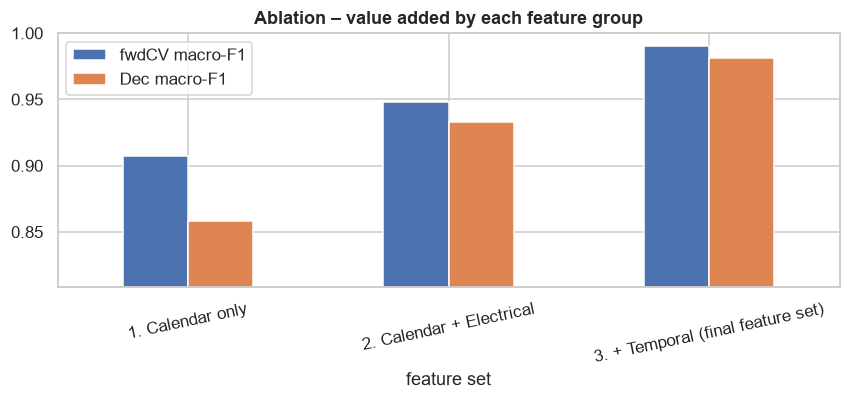

In [21]:

# Feature-group ablation:
# forward CV uses fold-specific features and caps.
# December remains a post-hoc diagnostic.

abl_sets = {
    "1. Calendar only": CAL,
    "2. Calendar + Electrical": CAL + ELEC,
    "3. + Temporal (final feature set)": ALL,
}

abl = []

for name, cols in abl_sets.items():
    # Correct: uses cached features prepared separately for each fold.
    cv_acc, cv_f1, cv_std, _ = cv_score(models[CHAMPION], cols)

    # Final fit: use caps fitted on all Jan-Nov training data.
    mdl = clone(models[CHAMPION]).fit(X_train[cols], y_train)
    dec_pred = mdl.predict(X_test[cols])
    dec_metrics = metrics_dict(y_test, dec_pred)

    abl.append({
        "feature set": name,
        "n_features": len(cols),
        "fwdCV acc": cv_acc,
        "fwdCV macro-F1": cv_f1,
        "fwdCV macro-F1 std": cv_std,
        "Dec acc": dec_metrics["accuracy"],
        "Dec macro-F1": dec_metrics["f1_macro"],
    })

abl = pd.DataFrame(abl).set_index("feature set")
display(abl.round(4))

ax = abl[["fwdCV macro-F1", "Dec macro-F1"]].plot.bar(
    figsize=(8, 3.8),
    rot=12,
)
ax.set_ylim(
    max(0, abl[["fwdCV macro-F1", "Dec macro-F1"]].min().min() - 0.05),
    1.0,
)
ax.set_title("Ablation – value added by each feature group")
savefig("08_ablation")


## 10. Packaging & inference tests


In [22]:
bundle = {
    "model": final_model, "caps": caps, "features": ALL, "classes": CLASSES, "schema_rename": RENAME,
    "winter_months": WINTER_MONTHS, "champion": CHAMPION, "selection_rule": f"simplest model within {MARGIN} of best forward-CV macro-F1",
    "trained_on": f"{df.loc[is_train,'timestamp'].min():%Y-%m-%d} .. {df.loc[is_train,'timestamp'].max():%Y-%m-%d}",
    "min_history_rows": LTP.MIN_HISTORY_ROWS,
    "history_note": "Rolling features use min_periods; short history is computed on a partial window (flagged by full_24h_history), never rejected.",
    "limitations": "Schedule learned from one plant and one year; December->Nov-Feb tariff assumed.",
    "versions": {"python": platform.python_version(), **{p: imd.version(p) for p in ["scikit-learn", "pandas", "numpy", "joblib"]}},
}
joblib.dump(bundle, OUT / "load_type_model.joblib")
print("saved bundle | versions:", bundle["versions"])

# Test 1 – fresh read of the ORIGINAL csv, reloaded model, no manual renaming
reloaded = LTP.load_bundle(OUT / "load_type_model.joblib")
fresh = pd.read_csv(DATA_PATH)
assert "Date_Time" in fresh.columns and "Usage_kWh" in fresh.columns            # truly the original schema
inf = predict_from_raw(fresh, reloaded)
inf_dec = inf[inf.timestamp >= TEST_START].reset_index(drop=True)
mism = int((inf_dec["predicted_load_type"].map(LABEL2ID).values != y_pred).sum())
assert len(inf_dec) == len(y_pred) and mism == 0, f"inference path differs from evaluation path ({mism} mismatches)"
print(f"✅ Test 1: fresh original CSV + reloaded model -> December predictions identical ({len(inf_dec):,} rows, 0 mismatches)")
inf_dec.to_csv(OUT / "december_predictions.csv", index=False)

saved bundle | versions: {'python': '3.11.0', 'scikit-learn': '1.9.1', 'pandas': '3.1.0', 'numpy': '2.4.6', 'joblib': '1.6.0'}
✅ Test 1: fresh original CSV + reloaded model -> December predictions identical (2,976 rows, 0 mismatches)


In [23]:
# Test 2 – clean interpreter that imports ONLY the shipped module and the saved bundle
snippet = (
    "import pandas as pd, load_type_pipeline as P\n"
    "b = P.load_bundle('outputs/load_type_model.joblib')\n"
    "o = P.predict_from_raw(pd.read_csv('load_data.csv'), b)\n"
    "o.to_csv('outputs/_subprocess_check.csv', index=False)\n")
cp = subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True, cwd=str(Path.cwd()))
assert cp.returncode == 0, cp.stderr[-800:]
sub = pd.read_csv(OUT / "_subprocess_check.csv"); (OUT / "_subprocess_check.csv").unlink()
sub_dec = sub[pd.to_datetime(sub.timestamp) >= TEST_START].reset_index(drop=True)
assert (sub_dec["predicted_load_type"].values == inf_dec["predicted_load_type"].values).all()
print("✅ Test 2: separate clean interpreter reproduces the same predictions")

# Test 3a – malformed input -> clear error
try:
    predict_from_raw(fresh.drop(columns=["Usage_kWh"]), reloaded)
except ValueError as ex:
    print("✅ Test 3a: missing column rejected ->", str(ex)[:110], "...")

# Test 3b – cold start: only December supplied (no November history) -> warning + flag, not rejection
dec_only = fresh[pd.to_datetime(fresh["Date_Time"], format="%d-%m-%Y %H:%M") >= TEST_START]
with warnings.catch_warnings(record=True) as wlist:
    warnings.simplefilter("always")
    short = predict_from_raw(dec_only.head(40), reloaded)
print("✅ Test 3b: 40 readings only ->", [str(w.message)[:95] for w in wlist][0], "| rows flagged without full history:", int((~short.full_24h_history).sum()), "of", len(short))
cold = predict_from_raw(dec_only, reloaded)
cold_acc_day1 = float((cold.predicted_load_type.map(LABEL2ID).values[:96] == y_test.values[:96]).mean())
warm_acc_day1 = float((y_pred[:96] == y_test.values[:96]).mean())
cold_acc_all = float((cold.predicted_load_type.map(LABEL2ID).values == y_test.values).mean())
print(f"Cold start (no November context):  1 Dec accuracy {cold_acc_day1:.3f} vs {warm_acc_day1:.3f} with history | whole December {cold_acc_all:.4f} vs {final_metrics['accuracy']:.4f}")

✅ Test 2: separate clean interpreter reproduces the same predictions
✅ Test 3a: missing column rejected -> Input is missing required column(s) ['Usage_kWh']. Expected the original CSV columns ['Date_Time', 'Usage_kWh' ...
✅ Test 3b: 40 readings only -> Only 40 readings supplied (< 96 = 24 h). Rolling 24 h features are computed on a partial window | rows flagged without full history: 40 of 40
Cold start (no November context):  1 Dec accuracy 0.760 vs 0.760 with history | whole December 0.9845 vs 0.9845


In [24]:
metrics_out = {
    "champion": CHAMPION, "selection": bundle["selection_rule"], "final_holdout": "2018-12", "n_test": int(len(y_test)),
    "december_exposure_note": "December also used in earlier exploratory prototyping; treat as indicative, not unbiased.",
    "forward_cv": cv_table.round(5).to_dict("index"), "december": {k: round(float(v), 5) for k, v in final_metrics.items()},
    "december_accuracy_boot95": [round(float(acc_lo), 5), round(float(acc_hi), 5)],
    "december_per_class": pc_final.round(5).to_dict("index"), "rule_baseline_december": pc_rule.round(5).to_dict("index"),
    "ablation": abl.round(5).to_dict("index"), "versions": bundle["versions"]}
json.dump(metrics_out, open(OUT / "metrics.json", "w"), indent=2, default=float)
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['december_predictions.csv', 'figures', 'load_type_model.joblib', 'metrics.json']


## 11. Conclusions – measured results vs. assumptions

In [25]:
rb, ch, du = cv_table.loc[RULE], cv_table.loc[CHAMPION], cv_table.loc["Dummy (most frequent)"]
rt = test_table.loc[RULE]
a1, a2, a3 = abl.iloc
tuned_gap = cv_table.loc[TUNED, "cv_f1_macro"] - cv_table.loc["HistGradientBoosting", "cv_f1_macro"]
same_dec = np.isclose(test_table.loc[TUNED, "accuracy"], test_table.loc["HistGradientBoosting", "accuracy"])
bd = bad_days.assign(d=bad_days.index.strftime("%d %b (%a)"))
err_txt = "; ".join(f"{r.d}: {int(r.errors)} ({r.true_pattern.lower()})" for r in bd.itertuples()) or "none"
L = []
L.append("### Measured results")
L.append(f"* **Champion:** `{CHAMPION}` – chosen by forward-CV with the pre-declared rule (simplest model within {MARGIN} of the best macro-F1).")
L.append(f"* **Forward-CV (Jul–Nov validation, strictly later than training):** champion macro-F1 **{ch.cv_f1_macro:.3f} ± {ch.cv_f1_std:.3f}** (accuracy {ch.cv_accuracy:.3f}); rule baseline {rb.cv_f1_macro:.3f}; dummy {du.cv_f1_macro:.3f}.")
L.append(f"* **December final hold-out (indicative, see section 1):** accuracy **{final_metrics['accuracy']:.4f}** (day-block bootstrap 95 % interval {acc_lo:.3f}–{acc_hi:.3f}); macro precision {final_metrics['precision_macro']:.3f}, recall {final_metrics['recall_macro']:.3f}, F1 {final_metrics['f1_macro']:.3f}; weighted F1 {final_metrics['f1_wtd']:.3f}.")
L.append(f"* **Per-class F1 (support):** " + ", ".join(f"{c} {pc_final.loc[c,'f1-score']:.3f} (n={int(pc_final.loc[c,'support'])})" for c in CLASSES) + ".")
L.append(f"* **Versus the simple rule baseline** (majority label per slot × season × weekday, fitted on training data only): December accuracy {rt.accuracy:.4f} / macro-F1 {rt.f1_macro:.3f} → the learned model adds **{final_metrics['accuracy']-rt.accuracy:+.3f}** accuracy and **{final_metrics['f1_macro']-rt.f1_macro:+.3f}** macro-F1.")
L.append(f"* **Feature groups (forward-CV macro-F1 / December macro-F1):** calendar only {a1['fwdCV macro-F1']:.3f} / {a1['Dec macro-F1']:.3f}; + electrical {a2['fwdCV macro-F1']:.3f} / {a2['Dec macro-F1']:.3f}; + temporal {a3['fwdCV macro-F1']:.3f} / {a3['Dec macro-F1']:.3f}.")
L.append(f"* **Errors in December:** {int(res.wrong.sum())} of {len(res):,} readings; by day → {err_txt}. {boundary_share:.0%} of errors lie next to a true label change.")
L.append(f"* **Tuning:** tuned vs. untuned HistGradientBoosting differ by {tuned_gap:+.4f} forward-CV macro-F1 (the tuned score is selection-biased); December accuracy is {'identical' if same_dec else 'different'} for the two. " + ("The extra complexity of tuning is therefore **not demonstrably worthwhile**." if abs(tuned_gap) <= MARGIN else "The tuned model clears the champion margin."))
L.append(f"* **Cold start:** with no history before 1 Dec the first-day accuracy is {cold_acc_day1:.3f} (vs {warm_acc_day1:.3f} with history); whole-December accuracy {cold_acc_all:.4f} vs {final_metrics['accuracy']:.4f}.")
display(Markdown("\n".join(L)))

### Measured results
* **Champion:** `Decision Tree` – chosen by forward-CV with the pre-declared rule (simplest model within 0.002 of the best macro-F1).
* **Forward-CV (Jul–Nov validation, strictly later than training):** champion macro-F1 **0.990 ± 0.008** (accuracy 0.991); rule baseline 0.930; dummy 0.224.
* **December final hold-out (indicative, see section 1):** accuracy **0.9845** (day-block bootstrap 95 % interval 0.966–0.997); macro precision 0.984, recall 0.979, F1 0.981; weighted F1 0.985.
* **Per-class F1 (support):** Light_Load 0.990 (n=1744), Medium_Load 0.976 (n=704), Maximum_Load 0.978 (n=528).
* **Versus the simple rule baseline** (majority label per slot × season × weekday, fitted on training data only): December accuracy 0.8871 / macro-F1 0.882 → the learned model adds **+0.097** accuracy and **+0.099** macro-F1.
* **Feature groups (forward-CV macro-F1 / December macro-F1):** calendar only 0.907 / 0.858; + electrical 0.948 / 0.933; + temporal 0.990 / 0.981.
* **Errors in December:** 46 of 2,976 readings; by day → 01 Dec (Sat): 23 (working day); 08 Dec (Sat): 9 (working day); 09 Dec (Sun): 1 (off-day); 15 Dec (Sat): 2 (off-day); 16 Dec (Sun): 1 (working day); 18 Dec (Tue): 1 (working day); 19 Dec (Wed): 1 (working day); 22 Dec (Sat): 1 (off-day); 23 Dec (Sun): 4 (off-day); 28 Dec (Fri): 1 (working day); 29 Dec (Sat): 2 (off-day). 26% of errors lie next to a true label change.
* **Tuning:** tuned vs. untuned HistGradientBoosting differ by -0.0001 forward-CV macro-F1 (the tuned score is selection-biased); December accuracy is different for the two. The extra complexity of tuning is therefore **not demonstrably worthwhile**.
* **Cold start:** with no history before 1 Dec the first-day accuracy is 0.760 (vs 0.760 with history); whole-December accuracy 0.9845 vs 0.9845.